In [1]:
import numpy as np
import pandas as pd

import sys
sys.path.insert(0, '../scripts')                 # utility.py lives in scripts/
from utility import AQI_CATEGORIES, aqi_to_category, prepare_dataset, split_train_val_test, evaluate

DATA_PATH = '../data/processed/aqi_weather_2015_2025.csv'
TARGET = 'tomorrow_status'
TREND = ['aqi_roll7_mean', 'aqi_roll7_std', 'aqi_diff1', 'aqi_dev7']

## 1. Load the data

In [2]:
DATA_PATH = '../data/processed/aqi_weather_2015_2025.csv'

df = pd.read_csv(DATA_PATH, parse_dates=['date'])
df = df.rename(columns={'aqi_value': 'aqi_today', 'air_quality_status': 'status_today'})
df = df.drop(columns=['split'])          # the split is rebuilt from `date` (split_train_val_test)
df = df.sort_values(['city', 'date']).reset_index(drop=True)
df.shape

(51072, 20)

## 2. Data cleaning

In [ ]:
df = prepare_dataset(DATA_PATH)                 # EDA pipeline: target, pollutant flags, gap filling, trend features
before = len(df)                                # count AFTER prepare_dataset, so only the next line is measured
df = df[df[TREND].notna().all(axis=1)]
print(f'Dropped {before - len(df)} rows with empty trend features')   # expect 195

## 3. Time-based split

In [ ]:
df_train, df_val, df_test = split_train_val_test(df)

for name, part in [('train', df_train), ('val', df_val), ('test', df_test)]:
    print(f"{name:5s} {len(part):6,} rows   {part['date'].min().date()} → {part['date'].max().date()}")

assert len(df_train) + len(df_val) + len(df_test) == len(df)    # no row lost or duplicated


train 33,543 rows   2015-05-05 → 2022-12-31
val    5,104 rows   2023-01-01 → 2023-12-31
test   9,985 rows   2024-01-01 → 2025-12-30


In [6]:
from utility import add_lr_features

# 1. The city normals: average pressure per city, training years only
city_pressure = df_train.groupby('city')['pressure_mean'].mean()

# 2. Add the three new feature groups to every split, using the SAME normals
df_train = add_lr_features(df_train, city_pressure)
df_val   = add_lr_features(df_val, city_pressure)
df_test  = add_lr_features(df_test, city_pressure)


In [7]:
df_train

,city,date,aqi_today,status_today,temp_mean,temp_max,temp_min,humidity_mean,dew_point_mean,precip_sum,...,aqi_imputed,aqi_roll7_mean,aqi_roll7_std,aqi_diff1,aqi_dev7,month,pressure_rel,precip_log,month_sin,month_cos
0,Bengaluru,2015-05-06,90.0,Satisfactory,25.22,30.1,21.2,67.29,18.34,3.8,...,0,109.200000,75.595635,-139.0,-24.000000,5,-0.812750,1.568616,5.000000e-01,-0.866025
1,Bengaluru,2015-05-07,52.0,Satisfactory,25.18,30.8,20.0,71.04,18.94,1.1,...,0,99.666667,71.533675,-38.0,-57.200000,5,0.157250,0.741937,5.000000e-01,-0.866025
2,Bengaluru,2015-05-08,83.0,Satisfactory,26.18,32.1,20.9,68.25,18.99,0.0,...,0,97.285714,65.604152,31.0,-16.666667,5,-0.422750,0.000000,5.000000e-01,-0.866025
3,Bengaluru,2015-05-09,46.0,Good,27.10,33.3,21.7,60.79,17.80,0.0,...,0,85.000000,66.070669,-37.0,-51.285714,5,-1.612750,0.000000,5.000000e-01,-0.866025
4,Bengaluru,2015-05-10,266.0,Poor,27.05,32.8,22.1,60.54,17.78,0.5,...,0,116.000000,92.132151,220.0,181.000000,5,-1.332750,0.405465,5.000000e-01,-0.866025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33538,Patna,2022-12-27,343.0,Very Poor,16.60,21.5,13.6,71.17,10.88,0.0,...,0,359.142857,24.714561,-9.0,-25.428571,12,7.465735,0.000000,-2.449294e-16,1.000000
33539,Patna,2022-12-28,336.0,Very Poor,14.68,19.8,10.6,74.00,9.83,0.0,...,0,349.714286,17.036376,-7.0,-23.142857,12,8.945735,0.000000,-2.449294e-16,1.000000
33540,Patna,2022-12-29,382.0,Very Poor,14.86,19.9,9.2,78.96,10.96,0.0,...,0,356.714286,18.979939,46.0,32.285714,12,10.515735,0.000000,-2.449294e-16,1.000000
33541,Patna,2022-12-30,424.0,Severe,15.20,20.5,11.5,81.25,11.80,0.0,...,0,363.857143,31.709245,42.0,67.285714,12,11.075735,0.000000,-2.449294e-16,1.000000


## 4. Feature selection

Logistic regression uses 23 columns: 15 numeric, 7 yes/no (6 pollutant flags + `aqi_imputed`) and `city`. `aqi_roll7_mean` is left out because it nearly duplicates `aqi_today` (VIF check in `aqi_prediction.ipynb`).

The checks below raise an error on any mismatch rather than training silently on bad input.

In [13]:
import pickle
import warnings
from pathlib import Path

from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [8]:
LR_NUMERIC = ['aqi_today', 'aqi_roll7_std', 'aqi_diff1', 'aqi_dev7',
              'temp_min', 'temp_range', 'humidity_mean', 'precip_log', 'pressure_rel',
              'cloud_cover_mean', 'wind_speed_mean', 'wind_u_mean', 'wind_v_mean',
              'month_sin', 'month_cos']
LR_BINARY = [c for c in df_train.columns if c.startswith('has_')] + ['aqi_imputed']
LR_CATEGORICAL = ['city']
FEATURES = LR_NUMERIC + LR_BINARY + LR_CATEGORICAL

print(f'{len(LR_NUMERIC)} numeric + {len(LR_BINARY)} yes/no + {len(LR_CATEGORICAL)} text = {len(FEATURES)} features')

15 numeric + 7 yes/no + 1 text = 23 features


In [9]:
# Stop early, with a clear message, if any split has a problem
for name, part in [('train', df_train), ('val', df_val)]:
    bad = part[FEATURES].columns[part[FEATURES].isna().any()].tolist()
    if bad:
        raise ValueError(f'{name}: missing values in {bad}')
    numeric = part[LR_NUMERIC + LR_BINARY]
    if not np.isfinite(numeric).all().all():
        raise ValueError(f'{name}: infinite values in the numeric features')

missing_classes = set(AQI_CATEGORIES) - set(df_train[TARGET].astype(str))
if missing_classes:
    raise ValueError(f'train has no rows for {missing_classes}: the model could never predict them')
print('Checks passed: no missing or infinite values; all six classes in train.')

Checks passed: no missing or infinite values; all six classes in train.


## 5. Rows to dictionaries

`DictVectorizer` takes one dictionary per row, the same format the web service receives (a JSON request), so training and prediction share one input format.

In [11]:
def to_records(part):
    """One dictionary per row: the input format of DictVectorizer and of the web service."""
    return part[FEATURES].to_dict(orient='records')

X_train, X_val = to_records(df_train), to_records(df_val)
y_train = df_train[TARGET].astype(str).to_numpy()
y_val = df_val[TARGET].astype(str).to_numpy()

X_train[0]
y_train

array(['Satisfactory', 'Satisfactory', 'Good', ..., 'Severe', 'Severe',
       'Severe'], shape=(33543,), dtype=object)

## 6. Build and train the model

One `Pipeline` with three steps, all fitted on the training years only:

| Step | What it does |
|---|---|
| `DictVectorizer` | `city` becomes 14 yes/no columns; numbers pass through unchanged |
| `StandardScaler` | Puts every column on the same scale (AQI runs 0–500, flags 0/1), so the regularisation treats them equally and the solver converges |
| `LogisticRegression` | `class_weight='balanced'` makes rare classes (Severe) count more; `C=1.0` is the default strength of regularisation |

Non-convergence raises an error instead of a warning.

In [80]:
def make_model(class_weight, regularisation=1.0, max_itr = 2000):
    return Pipeline([
        ('dv', DictVectorizer(sparse=False)),
        ('scale', StandardScaler()),
        ('lr', LogisticRegression(class_weight=class_weight, C=regularisation, max_iter=max_itr, random_state=1)),
    ])


In [23]:

model = make_model('balanced')

with warnings.catch_warnings():
    warnings.simplefilter('error', ConvergenceWarning)       # a model that did not converge is an error
    model.fit(X_train, y_train)

print('Columns after DictVectorizer:', len(model['dv'].feature_names_))
print('Classes, in the model\'s own (alphabetical) order:', list(model.classes_))

Columns after DictVectorizer: 36
Classes, in the model's own (alphabetical) order: ['Good', 'Moderate', 'Poor', 'Satisfactory', 'Severe', 'Very Poor']


## 7. Evaluate on validation (2023)

Same `evaluate` function as the baselines. The bar is **persistence: macro F1 0.651**.

In [15]:
pred_val = model.predict(X_val)

results = pd.DataFrame([
    evaluate('persistence (tomorrow = today)', y_val, df_val['status_today']),
    evaluate('logistic regression', y_val, pred_val),
]).set_index('model')
results.round(3)

,accuracy,macro_f1,recall_very_poor,recall_severe,precision_very_poor,precision_severe
model,,,,,,
persistence (tomorrow = today),0.710,0.651,0.668,0.529,0.674,0.519
logistic regression,0.663,0.598,0.641,0.725,0.590,0.303


Wins and losses split by change vs unchanged days (persistence is right on every unchanged day and wrong on every change day):

In [16]:
changed = df_val['status_today'].astype(str).to_numpy() != y_val
print(f'Change days: {changed.sum()} of {len(y_val)} ({changed.mean():.0%})')
print(f'Logistic regression gets {(pred_val[changed] == y_val[changed]).mean():.1%} of them right '
      f'(persistence: 0% by definition)')
print(f'... and keeps {(pred_val[~changed] == y_val[~changed]).mean():.1%} of the unchanged days right '
      f'(persistence: 100%)')

Change days: 1478 of 5104 (29%)
Logistic regression gets 35.5% of them right (persistence: 0% by definition)
... and keeps 78.8% of the unchanged days right (persistence: 100%)


In [17]:
cm = pd.DataFrame(confusion_matrix(y_val, pred_val, labels=AQI_CATEGORIES),
                  index=pd.Index(AQI_CATEGORIES, name='actual'),
                  columns=pd.Index(AQI_CATEGORIES, name='predicted'))
cm

predicted,Good,Satisfactory,Moderate,Poor,Very Poor,Severe
actual,,,,,,
Good,219,71,3,0,0,0
Satisfactory,299,1154,325,7,0,0
Moderate,4,228,1224,361,12,0
Poor,0,4,112,513,140,9
Very Poor,0,0,1,55,236,76
Severe,0,0,1,1,12,37


**Weights for *Severe tomorrow***, per standard deviation of each feature. Positive = more of this makes Severe more likely.

In [18]:
# Do the weights make sense? Weights for "Severe tomorrow" (per standard deviation of each feature)
coef = pd.DataFrame(model['lr'].coef_, index=model.classes_, columns=model['dv'].feature_names_)
severe = coef.loc['Severe', LR_NUMERIC].sort_values()
severe.round(2).to_frame('weight for Severe')

,weight for Severe
wind_speed_mean,-1.32
precip_log,-1.16
aqi_dev7,-1.05
temp_min,-0.95
month_sin,-0.70
pressure_rel,-0.43
humidity_mean,-0.41
aqi_diff1,0.00
month_cos,0.03
cloud_cover_mean,0.10


**Probabilities are returned in `model.classes_` order** (alphabetical, not Good → Severe). Always pair them with `model.classes_`, otherwise a probability can be shown under the wrong category.

In [19]:
# Probabilities come back in model.classes_ order (alphabetical), NOT in AQI_CATEGORIES order
proba = model.predict_proba(X_val[:1])[0]
example = pd.Series(proba, index=model.classes_).reindex(AQI_CATEGORIES)
print(df_val[['city', 'date', 'aqi_today', 'status_today', TARGET]].iloc[0].to_dict())
example.round(3).to_frame('probability')

{'city': 'Bengaluru', 'date': Timestamp('2023-01-01 00:00:00'), 'aqi_today': 93.0, 'status_today': 'Satisfactory', 'tomorrow_status': 'Satisfactory'}


,probability
Good,0.079
Satisfactory,0.595
Moderate,0.320
Poor,0.005
Very Poor,0.000
Severe,0.000


**Findings:**
- **The first logistic regression does not beat persistence.** Macro F1 **0.598** against **0.651**, accuracy 0.663 against 0.710.
- **It wins where persistence cannot:** **35.5% of the change days** right (persistence: 0%) and **37 of the 51 Severe days** caught (recall 0.73, against 0.53).
- **It breaks too many easy days:** only **78.8%** of the unchanged days right (persistence: 100%).
- **It predicts "Severe" far too often:** 122 times for 51 real Severe days (precision 0.30). Drift effect: `class_weight='balanced'` learned from a period with 3.1% Severe days, but 2023 has 1.0%.
- **The weights are plausible:** `aqi_today` dominates (+6.87). Strong wind, rain and warm nights lower the chance of Severe. A sudden jump above last week (`aqi_dev7`, −1.05) also lowers it, the same "AQI falls back after a spike" effect as in the EDA.

**Next:** the same model **without class weights** (section 9) shows the over-prediction of Severe comes from the class weights, not from `aqi_today`. Both versions are compared in the Discussion.

## 8. Save the model

One file with everything the web service needs:

| Key | Why it is needed |
|---|---|
| `model` | DictVectorizer + scaler + logistic regression |
| `city_pressure` | City normals from the training years, to compute `pressure_rel` for a new day |
| `features` | Which columns the model expects |
| `cities` | The service must reject any other city (DictVectorizer would silently ignore it) |
| `validation` | The scores above, for the record |

In [20]:
MODEL_DIR = Path('models')
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / 'lr_baseline.bin'

bundle = {
    'model': model,                                   # DictVectorizer + scaler + logistic regression
    'city_pressure': city_pressure.to_dict(),         # city normals from the training years (for pressure_rel)
    'features': {'numeric': LR_NUMERIC, 'binary': LR_BINARY, 'categorical': LR_CATEGORICAL},
    'categories': AQI_CATEGORIES,
    'cities': sorted(city_pressure.index),            # the service must reject any other city
    'validation': results.round(4).to_dict(orient='index'),
}
with open(MODEL_PATH, 'wb') as f:
    pickle.dump(bundle, f)
print(f'Saved: {MODEL_PATH.resolve()} ({MODEL_PATH.stat().st_size / 1024:.0f} KB)')

Saved: /Users/sshobhitggupta/Documents/datatalk_ml_zoomchamp/midterm_project/aqi_forcasting/models/lr_baseline.bin (5 KB)


In [21]:
# Load it back and check it gives the same predictions
with open(MODEL_PATH, 'rb') as f:
    loaded = pickle.load(f)
assert (loaded['model'].predict(X_val) == pred_val).all()
print('Reloaded model gives identical predictions.')

Reloaded model gives identical predictions.


## 9. Training without class weights

Same pipeline with `class_weight=None` (every day weighted equally), to test whether the over-prediction of Severe comes from the class weights or from the features.

In [ ]:
model_no_weights = make_model(None)

with warnings.catch_warnings():
    warnings.simplefilter('error', ConvergenceWarning)       # a model that did not converge is an error
    model_no_weights.fit(X_train, y_train)

print('Columns after DictVectorizer:', len(model_no_weights['dv'].feature_names_))
print('Classes, in the model\'s own (alphabetical) order:', list(model_no_weights.classes_))

In [73]:
pred_val_nw = model_no_weights.predict(X_val)

results_nw = pd.DataFrame([
    evaluate('persistence => (tomorrow = today )', y_val, df_val['status_today']),
    evaluate('logistic regression (balanced)', y_val, pred_val),
    evaluate('logistic regression, no class weights', y_val, pred_val_nw),
]).set_index('model')
results_nw.round(3)


,accuracy,macro_f1,recall_very_poor,recall_severe,precision_very_poor,precision_severe
model,,,,,,
persistence => (tomorrow = today ),0.710,0.651,0.668,0.529,0.674,0.519
logistic regression (balanced),0.663,0.598,0.641,0.725,0.590,0.303
"logistic regression, no class weights",0.729,0.647,0.764,0.392,0.680,0.645


### Prediction distribution check

Predicted vs actual share of each category: a bias check on the predictions, not *drift* (a change in the **data** over time, e.g. Severe falling from 3.1% of training days to 1.0% in 2023). Matching shares are necessary but not sufficient: a forecast can match them and still put the categories on the wrong days.

In [ ]:
right_nw = pred_val_nw == y_val
# share right on changed days:    right_nw[changed].mean()
# share right on unchanged days:  right_nw[~changed].mean()
list(right_nw)

# comparison = pd.DataFrame({
#     "predicted": pred_val_nw,
#     "actual": y_val
# })
# comparison["correct"] = comparison["predicted"] == comparison["actual"]
# comparison[~comparison["correct"]]   # show only the mistakes

dist = pd.DataFrame({
    "actual_pct": pd.Series(y_val).value_counts(normalize=True) * 100,
    "predicted_pct": pd.Series(pred_val_nw).value_counts(normalize=True) * 100
}).fillna(0)

dist["difference_pct_points"] = dist["predicted_pct"] - dist["actual_pct"]
print(dist.round(1))

In [59]:
def predicted_share(pred):
    return pd.Series(pred).value_counts(normalize=True).reindex(AQI_CATEGORIES, fill_value=0) * 100

dist = pd.DataFrame({
    'actual_pct': predicted_share(y_val),
    'no_weights_pct': predicted_share(pred_val_nw),
    'balanced_pct': predicted_share(pred_val),
})
dist['no_weights_ratio'] = dist['no_weights_pct'] / dist['actual_pct']
dist['balanced_ratio'] = dist['balanced_pct'] / dist['actual_pct']
dist.round(2)


,actual_pct,no_weights_pct,balanced_pct,no_weights_ratio,balanced_ratio
Good,5.74,2.92,10.23,0.51,1.78
Satisfactory,34.97,37.03,28.55,1.06,0.82
Moderate,35.83,36.44,32.64,1.02,0.91
Poor,15.24,14.91,18.36,0.98,1.20
Very Poor,7.21,8.09,7.84,1.12,1.09
Severe,1.00,0.61,2.39,0.61,2.39


**Weights for Severe, both models:** whether each weight changes direction or only size, and how the intercept (the starting value for Severe) differs. A higher intercept means a lower bar for predicting Severe.

In [ ]:
(pred_val_nw == 'Severe').sum()          # compare with (pred_val == 'Severe').sum() and 51 real Severe days

def severe_weights(m):
    coef = pd.DataFrame(m['lr'].coef_, index=m.classes_, columns=m['dv'].feature_names_)
    return coef.loc['Severe', LR_NUMERIC]

def severe_intercept(m):
    """The model's starting value for Severe, before any feature is added (one value per class)."""
    return pd.Series(m['lr'].intercept_, index=m.classes_)['Severe']

weights = pd.DataFrame({
    'balanced': severe_weights(model),
    'no class weights': severe_weights(model_no_weights),
})
print('Severe intercept: balanced', round(severe_intercept(model), 2),
      '| no class weights', round(severe_intercept(model_no_weights), 2))
weights.round(2)

### Confusion matrix

In [68]:
cm_nw = pd.DataFrame(confusion_matrix(y_val, pred_val_nw, labels=AQI_CATEGORIES),
                     index=pd.Index(AQI_CATEGORIES, name='actual'),
                     columns=pd.Index(AQI_CATEGORIES, name='predicted'))
cm_nw


predicted,Good,Satisfactory,Moderate,Poor,Very Poor,Severe
actual,,,,,,
Good,115,176,2,0,0,0
Satisfactory,33,1467,282,3,0,0
Moderate,1,243,1369,212,4,0
Poor,0,4,202,470,100,2
Very Poor,0,0,4,74,281,9
Severe,0,0,1,2,28,20


**One-vs-rest counts for Severe** (no-weights matrix above):

| Count | Meaning | Where in the table | Value |
|---|---|---|---|
| **TP** | Really Severe, predicted Severe | The diagonal cell | 20 |
| **FN** | Really Severe, predicted something else | The rest of the Severe **row**: 0+0+1+2+28 | 31 |
| **FP** | Not Severe, but predicted Severe | The rest of the Severe **column**: 0+0+0+2+9 | 11 |
| **TN** | Not Severe, not predicted Severe | Everything else: 5,104 − 20 − 31 − 11 | 5,042 |

Recall = TP ÷ (TP + FN) = 20 ÷ 51 = **0.39**; precision = TP ÷ (TP + FP) = 20 ÷ 31 = **0.65**. TN is not used by recall, precision or F1, which is why accuracy (dominated by TNs) can mislead on rare categories.

In [69]:
counts = pd.DataFrame({
    'TP': np.diag(cm_nw),
    'FN': cm_nw.sum(axis=1) - np.diag(cm_nw),          # row total minus the diagonal
    'FP': cm_nw.sum(axis=0) - np.diag(cm_nw),          # column total minus the diagonal
}, index=AQI_CATEGORIES)
counts['TN'] = cm_nw.values.sum() - counts['TP'] - counts['FN'] - counts['FP']
counts['recall'] = counts['TP'] / (counts['TP'] + counts['FN'])
counts['precision'] = counts['TP'] / (counts['TP'] + counts['FP'])
counts.round(2)


,TP,FN,FP,TN,recall,precision
Good,115,178,34,4777,0.39,0.77
Satisfactory,1467,318,423,2896,0.82,0.78
Moderate,1369,460,491,2784,0.75,0.74
Poor,470,308,291,4035,0.60,0.62
Very Poor,281,87,132,4604,0.76,0.68
Severe,20,31,11,5042,0.39,0.65


In [64]:
from sklearn.metrics import multilabel_confusion_matrix

mcm = multilabel_confusion_matrix(y_val, pred_val_nw, labels=AQI_CATEGORIES)
mcm[AQI_CATEGORIES.index('Severe')]        # [[TN, FP], [FN, TP]] for Severe


array([[5042,   11],
       [  31,   20]])

### Macro F1

F1 = 2 × precision × recall / (precision + recall) = 2·TP / (2·TP + FP + FN). Macro F1 = mean over the six categories.


In [70]:
counts['f1'] = 2 * counts['TP'] / (2 * counts['TP'] + counts['FP'] + counts['FN'])

macro_f1 = counts['f1'].mean()
print('Macro F1 (by hand):', round(macro_f1, 3))        # expect 0.647

counts[['TP', 'FP', 'FN', 'recall', 'precision', 'f1']].round(3)


Macro F1 (by hand): 0.647


,TP,FP,FN,recall,precision,f1
Good,115,34,178,0.392,0.772,0.520
Satisfactory,1467,423,318,0.822,0.776,0.798
Moderate,1369,491,460,0.748,0.736,0.742
Poor,470,291,308,0.604,0.618,0.611
Very Poor,281,132,87,0.764,0.680,0.720
Severe,20,11,31,0.392,0.645,0.488


In [71]:
from sklearn.metrics import f1_score
f1_score(y_val, pred_val_nw, labels=AQI_CATEGORIES, average=None).round(3)    # one F1 per class
f1_score(y_val, pred_val_nw, labels=AQI_CATEGORIES, average='macro')          # 0.647


0.6465195449480851

In [72]:
from sklearn.metrics import f1_score

# --- The three forecasts, all on the same validation days ---------------------------
pred_persistence = df_val['status_today'].astype(str).to_numpy()     # tomorrow = today

PREDICTIONS = {
    'balanced (first model)': pred_val,
    'no class weights': pred_val_nw,
    'persistence': pred_persistence,
}
MODELS = {                                                          # only the real models have weights
    'balanced (first model)': model,
    'no class weights': model_no_weights,
}
real_severe = (y_val == 'Severe').sum()
changed = pred_persistence != y_val                                 # days whose category changes overnight

# --- 1. Scores that every forecast has ------------------------------------------------
macro_f1, accuracy, said_severe = {}, {}, {}
severe_recall, severe_precision = {}, {}
change_right, unchanged_right = {}, {}

for name, pred in PREDICTIONS.items():
    macro_f1[name] = f1_score(y_val, pred, labels=AQI_CATEGORIES, average='macro')
    accuracy[name] = (pred == y_val).mean()                         # correct days / all days

    said_severe[name] = (pred == 'Severe').sum()
    tp = ((pred == 'Severe') & (y_val == 'Severe')).sum()           # said Severe, and it was Severe
    severe_recall[name] = tp / real_severe                          # caught / all real Severe days
    severe_precision[name] = tp / said_severe[name]                 # right / all "Severe" calls

    change_right[name] = (pred[changed] == y_val[changed]).mean()
    unchanged_right[name] = (pred[~changed] == y_val[~changed]).mean()

# --- 2. Values that only the logistic regression models have --------------------------
aqi_today_weight, severe_intercept = {}, {}

for name, m in MODELS.items():
    severe_row = list(m.classes_).index('Severe')                   # classes are in alphabetical order
    aqi_col = list(m['dv'].feature_names_).index('aqi_today')
    aqi_today_weight[name] = m['lr'].coef_[severe_row, aqi_col]
    severe_intercept[name] = m['lr'].intercept_[severe_row]

# --- 3. Build the table ---------------------------------------------------------------
def fmt(values, pattern):
    """Format one row; '—' for forecasts that do not have this value (persistence has no weights)."""
    return [pattern.format(values[name]) if name in values else '—' for name in PREDICTIONS]

comparison = pd.DataFrame({
    'Macro F1': fmt(macro_f1, '{:.3f}'),
    'Accuracy': fmt(accuracy, '{:.3f}'),
    f'Said "Severe" ({real_severe} real)': fmt(said_severe, '{}'),
    'Severe recall / precision': [f'{severe_recall[n]:.2f} / {severe_precision[n]:.2f}' for n in PREDICTIONS],
    'Change days right': fmt(change_right, '{:.1%}'),
    'Unchanged days right': fmt(unchanged_right, '{:.1%}'),
    'aqi_today weight for Severe': fmt(aqi_today_weight, '{:.2f}'),
    'Severe intercept': fmt(severe_intercept, '{:.2f}'),
}, index=list(PREDICTIONS)).T                                       # .T: metrics as rows, forecasts as columns

comparison


,balanced (first model),no class weights,persistence
Macro F1,0.598,0.647,0.651
Accuracy,0.663,0.729,0.710
"Said ""Severe"" (51 real)",122,31,52
Severe recall / precision,0.73 / 0.30,0.39 / 0.65,0.53 / 0.52
Change days right,35.5%,35.3%,0.0%
Unchanged days right,78.8%,88.3%,100.0%
aqi_today weight for Severe,6.87,7.21,—
Severe intercept,-5.25,-7.01,—


### Save the no-weights model

In [74]:
MODEL_DIR = Path('models')
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / 'lr_no_weights.bin'

bundle = {
    'model': model_no_weights,                                   # DictVectorizer + scaler + logistic regression
    'city_pressure': city_pressure.to_dict(),         # city normals from the training years (for pressure_rel)
    'features': {'numeric': LR_NUMERIC, 'binary': LR_BINARY, 'categorical': LR_CATEGORICAL},
    'categories': AQI_CATEGORIES,
    'cities': sorted(city_pressure.index),            # the service must reject any other city
    'validation': results_nw.round(4).to_dict(orient='index'),
}
with open(MODEL_PATH, 'wb') as f:
    pickle.dump(bundle, f)
print(f'Saved: {MODEL_PATH.resolve()} ({MODEL_PATH.stat().st_size / 1024:.0f} KB)')

Saved: /Users/sshobhitggupta/Documents/datatalk_ml_zoomchamp/midterm_project/aqi_forcasting/models/lr_no_weights.bin (5 KB)


## 10. "Dangerous" alert (Very Poor or Severe)

Both categories harm health, especially for children and older people. The model keeps the six categories (authorities act differently on Very Poor and Severe days); the **alert is derived from its prediction**: Dangerous = the forecast is Very Poor or Severe. With 419 real Dangerous days, it is also a much more stable measure than Severe alone (51 days).

In [77]:
BAD = ['Very Poor', 'Severe']                         # "Dangerous": Very Poor or worse
actual_bad = np.isin(y_val, BAD)

alert_rows = []
for name, pred in PREDICTIONS.items():
    alert = np.isin(pred, BAD)                        # the forecast raises a Dangerous alert
    hit = (alert & actual_bad).sum()                  # ... and the day really was Dangerous
    alert_rows.append({
        'forecast': name,
        'alerts raised': alert.sum(),
        'Dangerous days warned (recall)': hit / actual_bad.sum(),
        'alerts that were right (precision)': hit / alert.sum(),
    })

print('Real Dangerous days in 2023:', actual_bad.sum())
pd.DataFrame(alert_rows).set_index('forecast').round(3)

Real Dangerous days in 2023: 419


,alerts raised,Dangerous days warned (recall),alerts that were right (precision)
forecast,,,
balanced (first model),522,0.862,0.692
no class weights,444,0.807,0.761
persistence,417,0.749,0.753


## Discussion

Full reasoning, written for management: [`docs/model_decisions.md`](../docs/model_decisions.md).

**1. Class weights are a setting to tune, not a fixed choice.**

| Validation 2023 | Balanced | No class weights | Persistence |
|---|---|---|---|
| Macro F1 | 0.598 | 0.647 | **0.651** |
| Accuracy | 0.663 | **0.729** | 0.710 |
| Said "Severe" (51 real) | 122 | 31 | 52 |
| Change days right | 35.5% | 35.3% | 0% |
| Unchanged days right | 78.8% | 88.3% | 100% |

- The over-prediction of Severe comes from **the class weights, not from `aqi_today`**: without weights, the `aqi_today` weight is even larger (7.21 against 6.87), yet the model says Severe 31 times instead of 122.
- `'balanced'` makes a missed Severe day count about 7 times more, which **lowers the bar** for saying Severe (intercept −5.25 against −7.01). Because Severe days became rarer (3.1% of training days, 1.0% in 2023), the lowered bar produces many false alarms.
- Every weight that matters keeps its direction in both models; only its size changes. (`month_cos` flips sign, but it is close to zero in both: +0.03 and −0.05.)
- Without weights the model **ties with persistence** on macro F1 and beats it on accuracy. Its weak spots are the rare ends: it calls many Good days Satisfactory and many Severe days Very Poor.

**2. Misses vs false alarms.**

| 51 real Severe days | Balanced | No weights | Persistence |
|---|---|---|---|
| Caught | **37** | 20 | 27 |
| Missed | **14** | 31 | 24 |
| False alarms | 85 | **11** | 25 |

- Catching 17 more Severe days costs 74 more false alarms: about **4.4 false alarms per extra Severe day caught**. Which side to favour is a decision for the forecast's users.
- Most mistakes are near-misses: 76 of the balanced model's 85 false alarms were Very Poor days, and 28 of the no-weights model's 31 misses were forecast as Very Poor.
- The tool to set the balance: a **decision threshold on P(Severe)**, which changes only the Severe decision.

**3. "Dangerous" is an alert, not a new target.** Merging Very Poor and Severe into one class raises every score, persistence's too (0.651 → 0.693), so the model does not get better; the task gets easier. It would also hide the difference authorities act on (GRAP Stage II vs Stages III–IV). On the derived alert, the no-weights model already beats persistence on both recall and precision (table above).

**Next:** tune `C` and an intermediate class weight, try the variants without `humidity_mean` and without `city`, then tree models (decision tree, random forest, XGBoost), all scored with the same comparison table plus the misses / false alarms and Dangerous alert rows.

In [81]:
C_VALUES = sorted([0.1, 0.01, 0.001, 0.0001, 1, 10, 100])     # small C = strong L2 regularisation
WEIGHTS = {'balanced': 'balanced', 'no class weights': None}

rows, fitted = [], {}
for weight_name, class_weight in WEIGHTS.items():
    for C in C_VALUES:
        m = make_model(class_weight, C, 3000)
        with warnings.catch_warnings(record=True) as caught:      # record convergence problems instead of stopping
            warnings.simplefilter('always', ConvergenceWarning)
            m.fit(X_train, y_train)
        converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)

        pred_tr, pred_va = m.predict(X_train), m.predict(X_val)
        tp = ((pred_va == 'Severe') & (y_val == 'Severe')).sum()
        rows.append({
            'weights': weight_name,
            'C': C,
            'train_macro_f1': f1_score(y_train, pred_tr, labels=AQI_CATEGORIES, average='macro'),
            'val_macro_f1': f1_score(y_val, pred_va, labels=AQI_CATEGORIES, average='macro'),
            'val_accuracy': (pred_va == y_val).mean(),
            'said_severe': (pred_va == 'Severe').sum(),
            'severe_caught': tp,
            'severe_false_alarms': (pred_va == 'Severe').sum() - tp,
            'converged': converged,
        })
        fitted[(weight_name, C)] = m                              # keep every model, to save the best one

tuning = pd.DataFrame(rows)
tuning['gap'] = tuning['train_macro_f1'] - tuning['val_macro_f1']   # big gap = overfitting
tuning.round(3).assign(C=tuning['C'])                             # keep C unrounded (0.0001 would show as 0.0)


,weights,C,train_macro_f1,val_macro_f1,val_accuracy,said_severe,severe_caught,severe_false_alarms,converged,gap
0,balanced,0.0001,0.470,0.364,0.427,440,46,394,True,0.105
1,balanced,0.0010,0.539,0.446,0.509,268,46,222,True,0.093
2,balanced,0.0100,0.592,0.542,0.596,148,40,108,True,0.050
3,balanced,0.1000,0.619,0.587,0.649,128,38,90,True,0.032
4,balanced,1.0000,0.627,0.598,0.663,122,37,85,True,0.029
5,balanced,10.0000,0.627,0.601,0.665,121,37,84,True,0.026
6,balanced,100.0000,0.627,0.601,0.665,121,37,84,True,0.026
7,no class weights,0.0001,0.368,0.389,0.620,0,0,0,True,-0.022
8,no class weights,0.0010,0.482,0.478,0.664,1,0,1,True,0.004
9,no class weights,0.0100,0.575,0.567,0.704,8,6,2,True,0.008


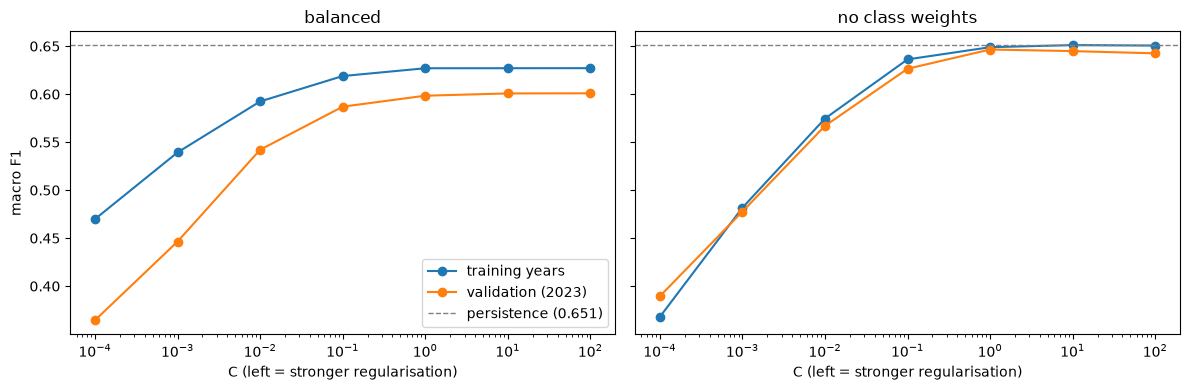

In [82]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (weight_name, part) in zip(axes, tuning.groupby('weights', sort=False)):
    ax.plot(part['C'], part['train_macro_f1'], marker='o', label='training years')
    ax.plot(part['C'], part['val_macro_f1'], marker='o', label='validation (2023)')
    ax.axhline(0.651, color='grey', linestyle='--', linewidth=1, label='persistence (0.651)')
    ax.set_xscale('log')                                       # C values span 0.0001 to 100
    ax.set_title(weight_name)
    ax.set_xlabel('C (left = stronger regularisation)')
axes[0].set_ylabel('macro F1')
axes[0].legend()
plt.tight_layout()
plt.show()


In [83]:
# Best = highest validation macro F1. If two are within 0.002, prefer the smaller C (simpler model).
best_score = tuning['val_macro_f1'].max()
best = (tuning[tuning['val_macro_f1'] >= best_score - 0.002]
        .sort_values('C')
        .iloc[0])
best_model = fitted[(best['weights'], best['C'])]
print(f"Best: {best['weights']}, C = {best['C']} -> validation macro F1 {best['val_macro_f1']:.3f} (persistence 0.651)")

MODEL_PATH = Path('models') / 'lr_best.bin'
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

bundle = {
    'model': best_model,
    'class_weight': WEIGHTS[best['weights']],
    'C': float(best['C']),
    'city_pressure': city_pressure.to_dict(),                  # needed for pressure_rel at prediction time
    'features': {'numeric': LR_NUMERIC, 'binary': LR_BINARY, 'categorical': LR_CATEGORICAL},
    'categories': AQI_CATEGORIES,
    'cities': sorted(city_pressure.index),                     # the service must reject any other city
    'validation': best.drop(['weights', 'C']).to_dict(),
    'tuning': tuning.round(4).to_dict(orient='records'),       # the whole table, for the record
}
with open(MODEL_PATH, 'wb') as f:
    pickle.dump(bundle, f)

with open(MODEL_PATH, 'rb') as f:                               # reload and check it predicts the same
    loaded = pickle.load(f)
assert (loaded['model'].predict(X_val) == best_model.predict(X_val)).all()
print(f'Saved and verified: {MODEL_PATH.resolve()}')


Best: no class weights, C = 1.0 -> validation macro F1 0.647 (persistence 0.651)
Saved and verified: /Users/sshobhitggupta/Documents/datatalk_ml_zoomchamp/midterm_project/aqi_forcasting/models/lr_best.bin
